# NYC Airbnb Open Data — Mini Project 1

Dataset: [dgomonov/new-york-city-airbnb-open-data](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data) (`AB_NYC_2019.csv`)

Setup: `uv sync`, then select the `.venv` kernel.

## Central question

Our question: **How much do borough and room type drive the nightly price of an NYC Airbnb?**

## 0. Setup

In [2]:
from pathlib import Path

import kagglehub

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split

sns.set_theme()
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

/opt/anaconda3/envs/jcp/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data Cleaning (Pandas)

### 1.1 Load

In [3]:
# Download latest version (cached after first run)
path = Path(kagglehub.dataset_download('dgomonov/new-york-city-airbnb-open-data'))
print('Path to dataset files:', path)

df_raw = pd.read_csv(path / 'AB_NYC_2019.csv')
print(df_raw.shape)
df_raw.head()

100%|██████████| 2.44M/2.44M [00:00<00:00, 7.23MB/s]

Extracting files...


Path to dataset files: /Users/antoine/.cache/kagglehub/datasets/dgomonov/new-york-city-airbnb-open-data/versions/3
(48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

### 1.2 Missing values

In [5]:
missing = pd.DataFrame({
    'n_missing': df_raw.isna().sum(),
    'pct_missing': (df_raw.isna().mean() * 100).round(2),
}).query('n_missing > 0').sort_values('pct_missing', ascending=False)
missing

,n_missing,pct_missing
last_review,10052,20.56
reviews_per_month,10052,20.56
host_name,21,0.04
name,16,0.03


In [6]:
no_review = df_raw['last_review'].isna()
print('last_review and reviews_per_month missing on the same rows:', (no_review == df_raw['reviews_per_month'].isna()).all())
print('number_of_reviews on those rows:', df_raw.loc[no_review, 'number_of_reviews'].unique())

last_review and reviews_per_month missing on the same rows: True
number_of_reviews on those rows: [0]


**Our missing-value decisions** (one line per column, with the % affected and why we dropped or imputed):

- `number_of_reviews`, `last_review`, `reviews_per_month` (20.56% missing in `last_review` and `reviews_per_month`): dropped as columns because they describe a listing's review history, not its price, so our question doesn't need them. Dropping the columns keeps every row. Dropping the 10,052 rows instead would throw away a fifth of the data and bias it, because those listings are pricier (next bullet). The two columns are missing on exactly the same rows, and every one of those rows has `number_of_reviews == 0`: the gaps mean "never reviewed", not lost data.
- `name`, `host_name` (0.03% / 0.04%): imputed with `'Unknown'`. That's only ~16–21 rows, and neither column is a model feature, so there's no reason to lose the rows' price, location, and room type.
- Missing values are correlated with price. Listings with no reviews have a mean price of $192.9 (median $120) vs. $142.3 (median $101) for reviewed listings. That's one more reason to drop the columns rather than the rows: dropping rows would skew our price data downward.

In [7]:
df = df_raw.drop(columns=['number_of_reviews', 'last_review', 'reviews_per_month'])

df[['name', 'host_name']] = df[['name', 'host_name']].fillna('Unknown')

df.isna().sum()

id                                0
name                              0
host_id                           0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

### 1.3 Strange values, inconsistencies, duplicates

These checks feed the "Faithfulness & Granularity" write-up in Section 2.

In [8]:
print('Duplicate listing ids:', df['id'].duplicated().sum())
print('Fully duplicated rows:', df.duplicated().sum())
print('Listings priced at $0:', (df['price'] == 0).sum())
print('Listings over $1,000/night:', (df['price'] > 1000).sum())
print('Minimum nights > 30:', (df['minimum_nights'] > 30).sum())
df[['price', 'minimum_nights', 'availability_365']].describe()

Duplicate listing ids: 0
Fully duplicated rows: 0
Listings priced at $0: 11
Listings over $1,000/night: 239
Minimum nights > 30: 747


,price,minimum_nights,availability_365
count,48895.000000,48895.000000,48895.000000
mean,152.720687,7.029962,112.781327
std,240.154170,20.510550,131.622289
min,0.000000,1.000000,0.000000
25%,69.000000,1.000000,0.000000
50%,106.000000,3.000000,45.000000
75%,175.000000,5.000000,227.000000
max,10000.000000,1250.000000,365.000000


**Our filtering decisions:** which rows did we remove and why?

We removed 971 rows (2.0%), leaving 47,924:
- **Minimum nights > 30 (747 rows):** these are effectively monthly or long-term rentals (the max is 1,250 nights, i.e. 3+ years), a different market from the short-term stays we're asking about. 30 is a natural cut-off: 3,760 listings set exactly 30, the usual line between short-term and monthly rentals.
- **Price = $0 (11 rows):** impossible as a real nightly price, so data-entry errors. They'd also break `log(price)`.
- **Price > $1,000 (239 rows, 0.5%):** OLS minimises squared error, so a handful of $5,000–$10,000 listings would pull the whole fit toward them. We keep $1–$1,000 to describe typical listings, and accept that we can't speak to the luxury tail.

No duplicates were found: 0 repeated listing ids and 0 fully duplicated rows.

In [9]:
PRICE_MIN, PRICE_MAX = 1, 1000
MAX_MIN_NIGHTS = 30

before = len(df)
df = df[df['price'].between(PRICE_MIN, PRICE_MAX) & (df['minimum_nights'] <= MAX_MIN_NIGHTS)]
print(f'Dropped {before - len(df):,} rows ({(before - len(df)) / before:.1%}); {len(df):,} remain')

Dropped 971 rows (2.0%); 47,924 remain


### 1.4 Group-by aggregation

In [10]:
df['neighbourhood_median_price'] = df.groupby('neighbourhood')['price'].transform('median')

borough_room = (
    df.groupby(['neighbourhood_group', 'room_type'])['price']
    .agg(['count', 'median', 'mean'])
    .round(1)
)
borough_room

count  median   mean
neighbourhood_group room_type                            
Bronx               Entire home/apt    369   100.0  128.9
                    Private room       648    53.5   63.2
                    Shared room         59    40.0   60.4
Brooklyn            Entire home/apt   9374   145.0  168.9
                    Private room     10014    65.0   72.9
                    Shared room        408    36.0   50.7
Manhattan           Entire home/apt  12738   190.0  225.7
                    Private room      7872    90.0  109.3
                    Shared room        471    69.0   89.4
Queens              Entire home/apt   2073   120.0  142.1
                    Private room      3339    60.0   68.4
                    Shared room        192    37.5   54.7
Staten Island       Entire home/apt    172   100.0  140.7
                    Private room       186    50.0   62.4
                    Shared room          9    30.0   57.4

What does this table say about our central question? Is median or mean the better summary here, and why?

Both factors matter, and room type matters most:
- **Room type:** in every borough an entire home/apt has roughly 1.9–2.2× the median price of a private room (Brooklyn $145 vs. $65; Manhattan $190 vs. $90), and shared rooms are cheapest.
- **Borough:** Manhattan is the most expensive for every room type (entire-home median $190 vs. $100 in the Bronx and Staten Island). Brooklyn is second; Queens, the Bronx, and Staten Island cluster together.
- **Median vs. mean:** the median is the better summary. In every group the mean is higher than the median (e.g. Manhattan entire homes: mean $225.7 vs. median $190), because a few expensive listings pull the mean up (right skew, see 3.2). Some groups are also small (Staten Island shared rooms: 9 listings), so their numbers are noisy either way.

### 1.5 Derived / engineered columns

In [11]:
df['price_per_week'] = df['price'] * 7
df['name_length'] = df['name'].str.len()
df['log_price'] = np.log(df['price'])

df[['price', 'price_per_week', 'name_length', 'log_price']].head()

,price,price_per_week,name_length,log_price
0,149,1043,34,5.003946
1,225,1575,21,5.416100
2,150,1050,35,5.010635
3,89,623,31,4.488636
4,80,560,48,4.382027


We engineered three columns:
- `price_per_week` (`price * 7`): the cost of a one-week stay, a more intuitive number for a traveller. Caveat: 6,548 listings have a minimum stay of 8–30 nights, so a 7-night booking isn't actually possible for them.
- `name_length` (`.str.len()`): length of the listing title, a quick check on whether hosts who write more charge more. It barely does (r = 0.10).
- `log_price`: a log-transformed price, used for the colour scale in the map and as a possible model target (see 3.2).

Plus `neighbourhood_median_price` from the group-by in 1.4.

### 1.6 Save cleaned data for the dashboard

In [12]:
CLEAN_PATH = Path('data') / 'airbnb_clean.csv'
CLEAN_PATH.parent.mkdir(exist_ok=True)
df.to_csv(CLEAN_PATH, index=False)
print(f'Saved {len(df):,} rows x {df.shape[1]} columns to {CLEAN_PATH}')

Saved 47,924 rows x 17 columns to data/airbnb_clean.csv


## 2. EDA: Faithfulness & Granularity

This text goes in the dashboard or README. Helper facts below.

In [13]:
print('Rows:', len(df_raw), '| unique listing ids:', df_raw['id'].nunique(), '| unique hosts:', df_raw['host_id'].nunique())
last_review = pd.to_datetime(df_raw['last_review'])
print('Last-review dates (raw data):', last_review.min().date(), 'to', last_review.max().date())
print('Boroughs:', df['neighbourhood_group'].nunique(), '| neighbourhoods:', df['neighbourhood'].nunique())
print('Hosts with 10+ listings:', df.loc[df['calculated_host_listings_count'] >= 10, 'host_id'].nunique())
df['neighbourhood_group'].value_counts()

Rows: 48895 | unique listing ids: 48895 | unique hosts: 37457
Last-review dates (raw data): 2011-03-28 to 2019-07-08
Boroughs: 5 | neighbourhoods: 221
Hosts with 10+ listings: 114


neighbourhood_group
Manhattan        21081
Brooklyn         19796
Queens            5604
Bronx             1076
Staten Island      367
Name: count, dtype: int64

**Faithfulness & Granularity**

- **What does each row represent?** One Airbnb listing (a whole home, private room, or shared room) as it appeared on the site when the data was collected. It is *not* a booking, a stay, or a host: 37,457 hosts own the 48,895 listings, and one host (Sonder (NYC)) runs 327 of them.
- **What is the scope?** (place, time period, which listings are included or missing) All five NYC boroughs, 221 neighbourhoods, captured in a single snapshot around July 2019. Last-review dates run from 2011-03-28 to 2019-07-08, and about two-thirds (65%) of reviewed listings were last reviewed in 2019. It's one point in time, not a time series, so it can't show seasonal or year-over-year price changes, and it excludes listings already removed from the site before the snapshot. After cleaning, our analysis covers short-term listings (minimum stay ≤ 30 nights) priced $1–$1,000.
- **Strange values, inconsistencies, duplicates we considered:** (refer to 1.3: $0 prices, extreme prices/minimum nights, multi-listing hosts, `price` is the *asking* price not what guests actually paid)
  - 11 listings priced at $0 and 239 above $1,000 (max $10,000): removed, see 1.3.
  - Minimum stays up to 1,250 nights: 747 listings over 30 nights removed as long-term rentals.
  - No duplicate listing ids or duplicate rows.
  - Multi-listing hosts: commercial operators with hundreds of listings sit alongside individuals renting one room, so a few hosts carry a lot of weight in the data.
  - `price` is the host's *asking* nightly price at the snapshot. It isn't what guests actually paid: no cleaning fees, discounts, or seasonal pricing.
  - Review fields were missing for the 20.6% of listings that have never been reviewed. These columns were dropped (see 1.2).

## 3. Visualizations

### 3.1 Categorical distribution: bar plot

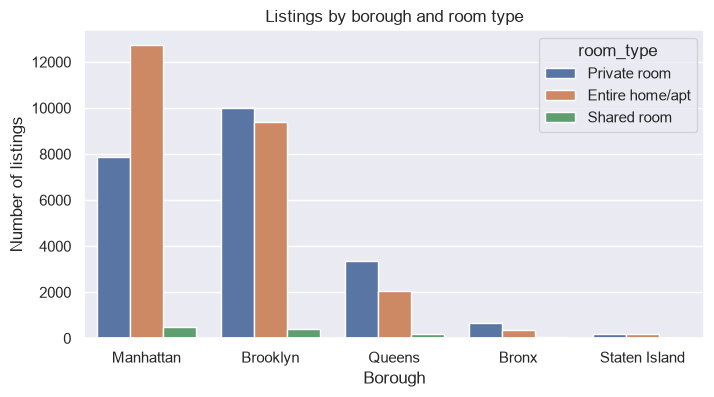

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=df, x='neighbourhood_group', hue='room_type', ax=ax,
              order=df['neighbourhood_group'].value_counts().index)
ax.set(title='Listings by borough and room type', xlabel='Borough', ylabel='Number of listings')
plt.show()

### 3.2 Quantitative distribution: histogram

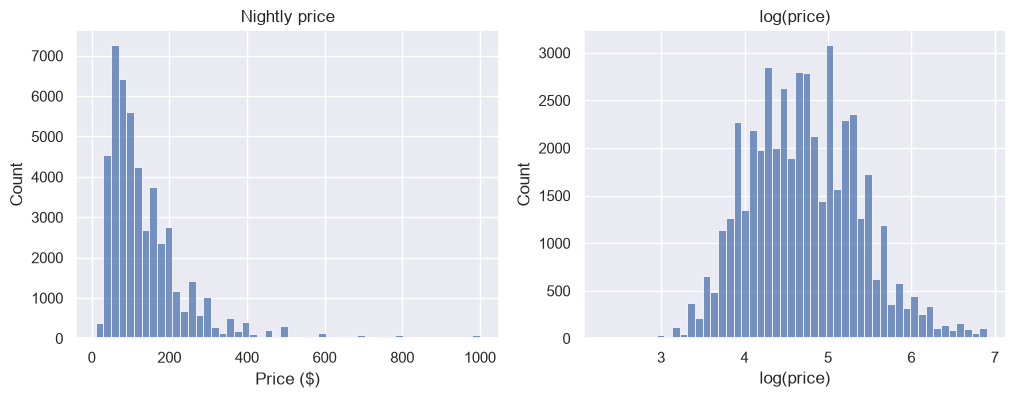

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], bins=50, ax=axes[0])
axes[0].set(title='Nightly price', xlabel='Price ($)')
sns.histplot(df['log_price'], bins=50, ax=axes[1])
axes[1].set(title='log(price)', xlabel='log(price)')
plt.show()

What shape is the price distribution? Does that change whether we should model `price` or `log_price`?

Price is strongly right-skewed (skewness 2.94): the middle half of listings costs $69–$175, with a long tail toward $1,000. That's why the mean ($141) is well above the median ($105). After a log transform, the distribution is close to symmetric (skewness 0.31).

This argues for `log_price` as the target: OLS fits better when errors are roughly symmetric, and on a log scale the coefficients mean "% more expensive", which suits multiplicative effects like "Manhattan costs more". We kept `price` as the target so coefficients read directly in dollars for a non-technical audience, and we accept the cost: the model handles the high end poorly (see Section 5). Switching to `log_price` is a future improvement.

### 3.3 Relationship between two variables: scatter

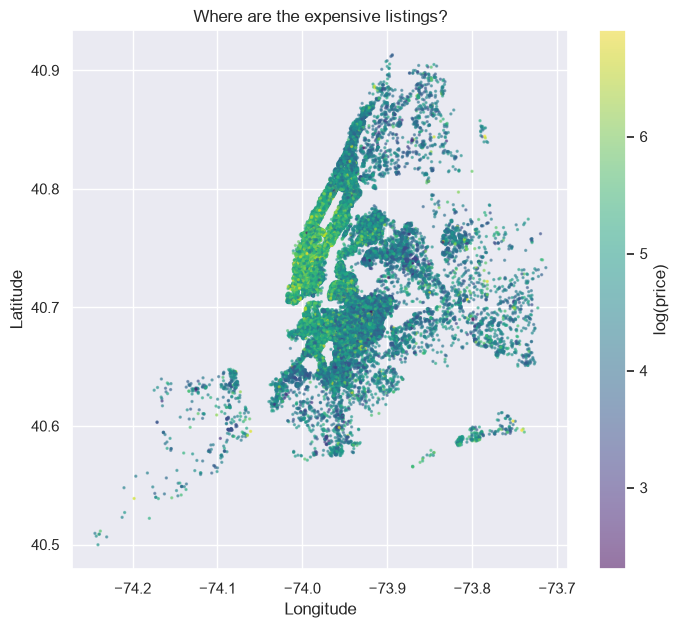

In [16]:
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(df['longitude'], df['latitude'], c=df['log_price'], s=2, alpha=0.5, cmap='viridis')
fig.colorbar(sc, ax=ax, label='log(price)')
ax.set(title='Where are the expensive listings?', xlabel='Longitude', ylabel='Latitude')
plt.show()

### 3.4 Bonus: correlation heatmap

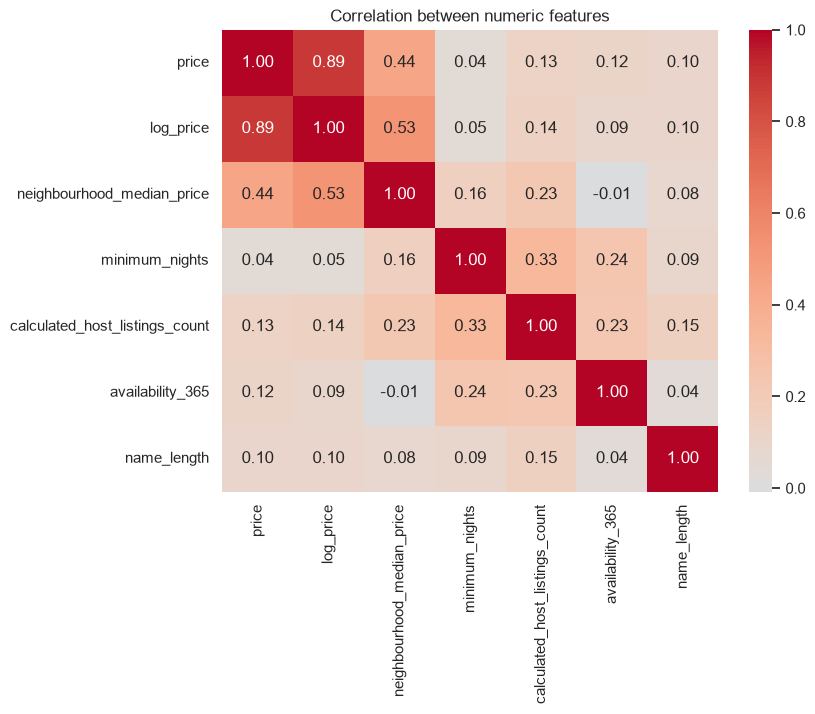

In [17]:
num_cols = ['price', 'log_price', 'neighbourhood_median_price', 'minimum_nights',
            'calculated_host_listings_count', 'availability_365', 'name_length']
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation between numeric features')
plt.show()

Which numeric features are (and aren't) correlated with price? This tells you how much the model will need the categorical features.

None of the plain numeric features are meaningfully correlated with price: `calculated_host_listings_count` r = 0.13, `availability_365` r = 0.12, `name_length` r = 0.10, `minimum_nights` r = 0.04. The only strong one is `neighbourhood_median_price` (r = 0.44), and it's built from price itself, so it can't be a feature. What it does show is that *location* carries the signal.

The map (3.3) agrees. The priciest 10% of listings are concentrated in Manhattan: 16% of Manhattan listings are in that top group vs. 3–6% in other boroughs, led by Midtown, Hell's Kitchen, and the Upper West Side, with Williamsburg the Brooklyn exception. So numeric features alone will barely beat the constant model, and the model will need the one-hot encoded borough and room type.

## 4. One-Hot Encoding

We split **before** encoding so the test set stays unseen. Fixing each column's categories from the training set means `drop_first` always drops the same reference level, and train/test always get identical columns, even if a rare category is missing from one split.

In [18]:
TARGET = 'price'
CATEGORICAL = ['neighbourhood_group', 'room_type']
NUMERIC = ['minimum_nights', 'availability_365', 'calculated_host_listings_count']

train, test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
print(f'Train: {len(train):,} rows | Test: {len(test):,} rows')


categories = {c: sorted(train[c].unique()) for c in CATEGORICAL}

def make_features(data):
    cats = pd.DataFrame({c: pd.Categorical(data[c], categories=categories[c]) for c in CATEGORICAL}, index=data.index)
    dummies = pd.get_dummies(cats, drop_first=True, dtype=int)
    return pd.concat([data[NUMERIC], dummies], axis=1)

X_train, X_test = make_features(train), make_features(test)
y_train, y_test = train[TARGET], test[TARGET]

assert list(X_train.columns) == list(X_test.columns)
print('Reference levels (dropped):', {c: cats[0] for c, cats in categories.items()})
X_train.head()

Train: 38,339 rows | Test: 9,585 rows
Reference levels (dropped): {'neighbourhood_group': 'Bronx', 'room_type': 'Entire home/apt'}


,minimum_nights,availability_365,calculated_host_listings_count,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
12764,5,0,1,0,1,0,0,0,0
26758,2,77,1,1,0,0,0,0,0
8846,2,52,1,1,0,0,0,1,0
48469,7,343,1,1,0,0,0,0,0
11936,7,0,2,0,1,0,0,1,0


**Reference levels we dropped:**

We dropped **Bronx** for `neighbourhood_group` and **Entire home/apt** for `room_type` (the first alphabetically, via `drop_first=True`). Every borough/room-type coefficient is therefore measured *relative to* a Bronx entire home.

If we kept every dummy column, each row's borough dummies would always sum to 1, which is exactly the intercept column. That's perfect multicollinearity. The model can't tell the intercept apart from the dummies, so infinitely many coefficient combinations give the same predictions, and the individual coefficients become meaningless. Dropping one level per category removes the redundancy.

## 5. A Simple Model

In [19]:
def evaluate(name, y_true, y_pred):
    return {'model': name, 'RMSE': root_mean_squared_error(y_true, y_pred), 'MAE': mean_absolute_error(y_true, y_pred)}

# Constant model: always predict the training mean
const_pred = np.full(len(y_test), y_train.mean())

# OLS without the encoded features (numeric only)
ols_numeric = LinearRegression().fit(X_train[NUMERIC], y_train)

# OLS with numeric + one-hot encoded features
ols_full = LinearRegression().fit(X_train, y_train)

# Note: if TARGET is log_price, these errors are in log units, not dollars.
results = pd.DataFrame([
    evaluate('Constant (train mean)', y_test, const_pred),
    evaluate('OLS: numeric only', y_test, ols_numeric.predict(X_test[NUMERIC])),
    evaluate('OLS: numeric + one-hot', y_test, ols_full.predict(X_test)),
]).round(2)
results

,model,RMSE,MAE
0,Constant (train mean),116.21,77.03
1,OLS: numeric only,114.88,75.78
2,OLS: numeric + one-hot,97.04,56.87


In [20]:
print('Intercept:', round(ols_full.intercept_, 2))
pd.Series(ols_full.coef_, index=X_train.columns).sort_values().round(2)

Intercept: 135.82


room_type_Shared room               -129.32
room_type_Private room              -102.80
minimum_nights                        -1.41
neighbourhood_group_Staten Island     -1.10
availability_365                       0.13
calculated_host_listings_count         0.16
neighbourhood_group_Queens            11.31
neighbourhood_group_Brooklyn          29.87
neighbourhood_group_Manhattan         77.45
dtype: float64

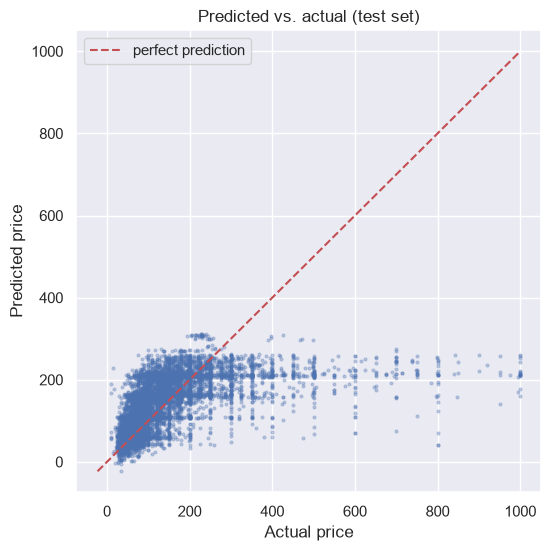

In [21]:
test_pred = ols_full.predict(X_test)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, test_pred, s=4, alpha=0.3)
lims = [min(y_test.min(), test_pred.min()), max(y_test.max(), test_pred.max())]
ax.plot(lims, lims, 'r--', label='perfect prediction')
ax.set(xlabel=f'Actual {TARGET}', ylabel=f'Predicted {TARGET}', title='Predicted vs. actual (test set)')
ax.legend()
plt.show()

**Model write-up**

- **Train/test split:** 80/20 random split (`random_state=42`), 38,339 rows train / 9,585 rows test.
- **Coefficient interpretation** (plain language, relative to the reference level): "Listings in **Manhattan** are predicted to cost about **$77 more** per night than listings in the **Bronx**, holding room type, minimum nights, availability, and host listing count constant." Likewise, "a **private room** is predicted to cost about **$103 less** than an **entire home/apt**, holding the other features constant." Room type moves price more than any borough does.
- **Did one-hot encoding help?** Compare the two OLS rows in the results table: Yes, a lot. The numeric-only model barely beats the constant model (RMSE $114.88 vs. $116.21). Adding the encoded borough and room type drops RMSE to $97.04 (−16%) and MAE from $75.78 to $56.87 (−25%). Almost all of the model's predictive power comes from the encoded features.
- **Evaluation observation:** (look at the plot: where does the model miss, e.g. underpredicting at the high end?) The model **underpredicts at the high end and overpredicts at the low end.** For the most expensive fifth of test listings ($199–$1,000), it predicts about $116 less than the actual price on average. Its highest prediction is only ~$311, while actual prices reach $1,000. For the cheapest fifth ($10–$60), it overpredicts by about $27, and 4 predictions are even negative. A linear model on raw price with only a few categories can't reach the extremes. Modelling `log_price` or adding neighbourhood-level location would likely help.